# 3D U-Net Baseline for Glioma Segmentation

## Model Architecture

The baseline model is a **3D U-Net**, a convolutional encoder-decoder
architecture designed for volumetric medical image segmentation.

Unlike 2D U-Net, it uses 3D convolutions to learn spatial features
across all three dimensions of MRI volumes.

### Architecture overview

- **Input:** 4 MRI modalities (FLAIR, T1, T1ce, T2).
- **Encoder:** progressively extracts features and reduces spatial resolution.
- **Bottleneck:** captures high-level volumetric representations.
- **Decoder:** progressively restores spatial resolution.
- **Skip connections:** transfer spatial information from encoder
  to decoder, helping preserve anatomical details.
- **Output:** 4 segmentation classes (background and three tumor subregions).

### Experimental configuration

| Parameter | Value |
|---|---|
| Architecture | 3D U-Net |
| Input channels | 4 |
| Output classes | 4 |
| Initial filters | 8 |
| Patch size | 64 × 64 × 64 |
| Batch size | 2 |
| Loss | Dice + Cross Entropy |
| Optimizer | AdamW |
| Validation | 5-fold cross-validation |

### Evaluation metrics

Dice coefficient, Intersection over Union (IoU),
Hausdorff Distance (HD) and HD95.

The model will be evaluated separately on necrotic core,
FLAIR signal hyperintensity and enhancing tumor.

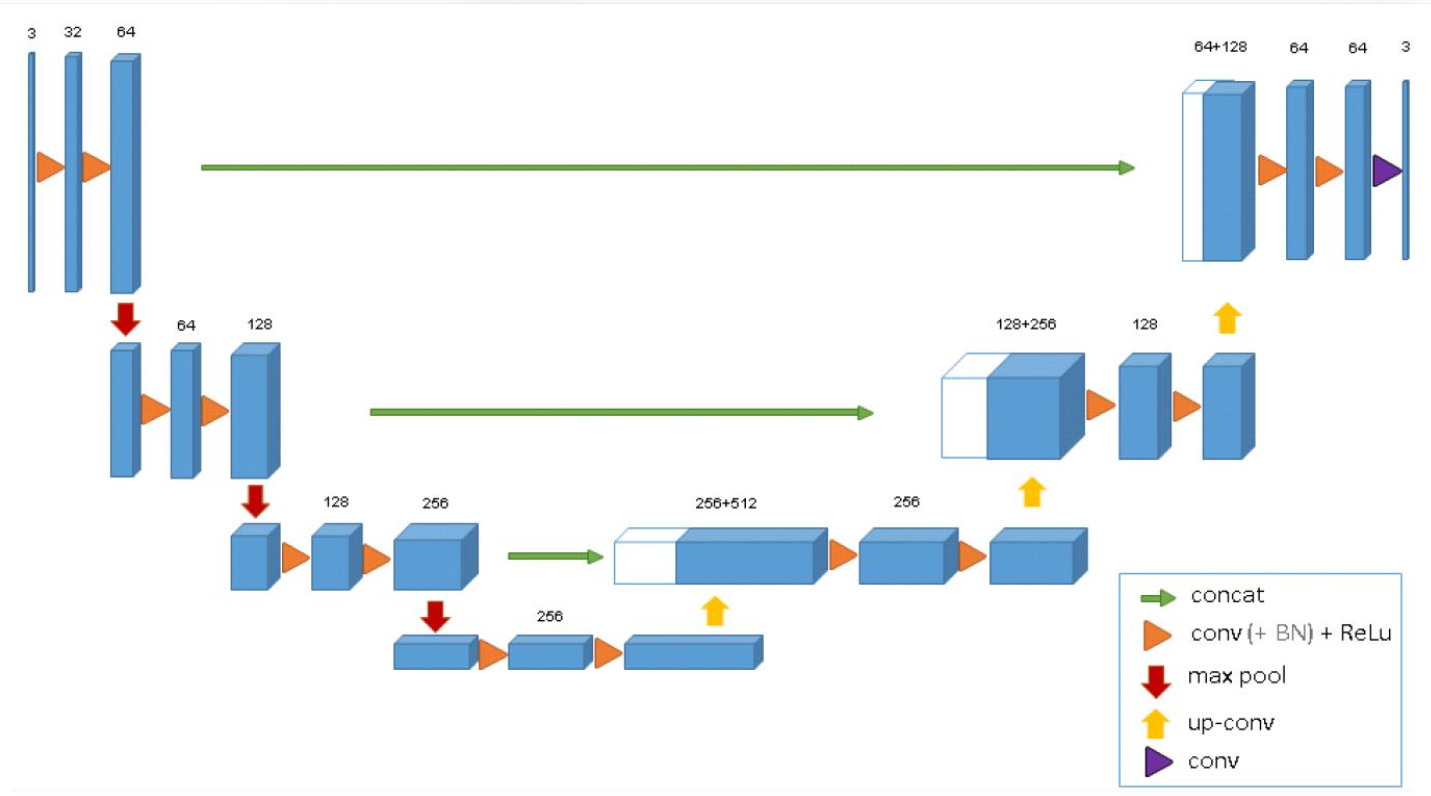

In [31]:
# ================================================================
# CELL 1 - IMPORT LIBRARIES
# ================================================================

import os
import gc
import json
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import nibabel as nib

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import StratifiedKFold, KFold

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

# ================================================================
# CELL 2 - GENERAL CONFIGURATION
# ================================================================

# -------------------------------
# Dataset paths
# -------------------------------

IMAGES_DIR = Path(
    "/kaggle/input/datasets/laurapitton/training-images/Training_images"
)

# MODIFICA questo percorso con quello effettivo del tuo manifest
MANIFEST_PATH = Path(
    "/kaggle/input/datasets/liviapantarotto/segmentation-manifest/segmentation_manifest.csv"
)

# -------------------------------
# Output directory
# -------------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/glioma_3d_unet_baseline"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

RESULTS_DIR = OUTPUT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# -------------------------------
# Reproducibility
# -------------------------------

SEED = 42

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# -------------------------------
# Device configuration
# -------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print("Number of GPUs:", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):
        print(
            f"GPU {i}:",
            torch.cuda.get_device_name(i)
        )

# -------------------------------
# Initial training parameters
# -------------------------------

N_FOLDS = 5

PATCH_SIZE = (64, 64, 64)

BATCH_SIZE = 2

NUM_WORKERS = 0

MAX_EPOCHS = 50

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-5

PATIENCE = 10

BASE_CHANNELS = 8

MODALITIES = [
    "FLAIR",
    "T1",
    "T1CE",
    "T2"
]

NUM_INPUT_CHANNELS = 4
NUM_CLASSES = 4

print("\nConfiguration completed.")

Libraries imported successfully.
Device: cpu

Configuration completed.


In [4]:
# ================================================================
# CELL 3 - CHECK DATASET PATHS
# ================================================================

print("Checking dataset paths...\n")

print(
    "MRI directory:",
    IMAGES_DIR.exists()
)

print(
    "Manifest file:",
    MANIFEST_PATH.exists()
)

if not IMAGES_DIR.exists():
    raise FileNotFoundError(
        f"MRI directory not found: {IMAGES_DIR}"
    )

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Manifest not found: {MANIFEST_PATH}\n"
        "Please update MANIFEST_PATH in Cell 2."
    )

print("\nAll required paths are available.")

# ================================================================
# CELL 4 - LOAD SEGMENTATION MANIFEST
# ================================================================

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest loaded successfully.")
print("Number of patients:", len(manifest))

print("\nAvailable columns:")
print(manifest.columns.tolist())

display(manifest.head())

# ================================================================
# CELL 5 - VALIDATE MANIFEST
# ================================================================

REQUIRED_COLUMNS = [
    "patient_folder",
    "FLAIR_path",
    "T1_path",
    "T1CE_path",
    "T2_path",
    "MASK_path",
    "split",
    "Cohort ID"
]

# Check required columns
missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in manifest: {missing_columns}"
    )

# Check split distribution
print("Original split distribution:")
print(manifest["split"].value_counts(dropna=False))

print("\nPatients per cohort:")
print(manifest["Cohort ID"].value_counts(dropna=False))

# Check duplicate patients
print(
    "\nDuplicate patient folders:",
    manifest["patient_folder"].duplicated().sum()
)

# Check missing values in essential columns
print("\nMissing values:")
display(
    manifest[REQUIRED_COLUMNS].isna().sum()
)

# Check expected patient counts
assert len(manifest) == 1180, (
    f"Expected 1180 patients, found {len(manifest)}"
)

assert manifest["patient_folder"].is_unique, (
    "Duplicate patient folders detected."
)

print("\nManifest validation completed.")

Checking dataset paths...

MRI directory: True
Manifest file: True

All required paths are available.
Manifest loaded successfully.
Number of patients: 1180

Available columns:
['patient_key', 'patient_folder', 'Cohort ID', 'split', 'is_labeled', 'is_unlabeled', 'use_for_mae', 'use_for_segmentation', 'FLAIR', 'T1', 'T1CE', 'T2', 'ALL_MODALITIES_PRESENT', 'FLAIR_path', 'T1_path', 'T1CE_path', 'T2_path', 'MASK', 'MASK_path', 'MRI_COMBINATION']


,patient_key,patient_folder,Cohort ID,split,is_labeled,is_unlabeled,use_for_mae,use_for_segmentation,FLAIR,T1,T1CE,T2,ALL_MODALITIES_PRESENT,FLAIR_path,T1_path,T1CE_path,T2_path,MASK,MASK_path,MRI_COMBINATION
0,1,1,1,validation,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
1,10,10,2,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
2,1000,1000,8,test,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
3,1001,1001,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
4,1002,1002,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2


Original split distribution:
split
train         826
validation    177
test          177
Name: count, dtype: int64

Patients per cohort:
Cohort ID
8    378
4    348
7    233
5     94
6     65
2     33
3     25
1      4
Name: count, dtype: int64

Duplicate patient folders: 0

Missing values:


patient_folder    0
FLAIR_path        0
T1_path           0
T1CE_path         0
T2_path           0
MASK_path         0
split             0
Cohort ID         0
dtype: int64


Manifest validation completed.


In [6]:
# ================================================================
# CELL 6 - DEVELOPMENT AND TEST SET
# ================================================================

development_df = manifest[
    manifest["split"].isin(["train", "validation"])
].copy().reset_index(drop=True)

test_df = manifest[
    manifest["split"] == "test"
].copy().reset_index(drop=True)

print("Development patients:", len(development_df))
print("Independent test patients:", len(test_df))

assert len(development_df) == 1003
assert len(test_df) == 177

# Verify patient-level separation
development_ids = set(
    development_df["patient_folder"].astype(str)
)

test_ids = set(
    test_df["patient_folder"].astype(str)
)

assert development_ids.isdisjoint(test_ids), (
    "Data leakage detected between development and test sets!"
)

print("\nNo patient overlap between development and test.")

# ================================================================
# CELL 7 - VERIFY MRI AND MASK FILES
# ================================================================

PATH_COLUMNS = [
    "FLAIR_path",
    "T1_path",
    "T1CE_path",
    "T2_path",
    "MASK_path"
]

missing_files = []

for _, row in manifest.iterrows():

    patient = row["patient_folder"]

    for column in PATH_COLUMNS:

        path = row[column]

        if not isinstance(path, str) or not Path(path).is_file():

            missing_files.append({
                "patient": patient,
                "column": column,
                "path": path
            })

missing_files_df = pd.DataFrame(missing_files)

print("Missing files:", len(missing_files_df))

if len(missing_files_df) > 0:

    display(missing_files_df.head(20))

    raise FileNotFoundError(
        "Some MRI or mask files are missing. "
        "Check the manifest paths before training."
    )

print("\nAll MRI volumes and masks are accessible.")

# ================================================================
# CELL 7 - VERIFY MRI AND MASK FILES
# ================================================================

PATH_COLUMNS = [
    "FLAIR_path",
    "T1_path",
    "T1CE_path",
    "T2_path",
    "MASK_path"
]

missing_files = []

for _, row in manifest.iterrows():

    patient = row["patient_folder"]

    for column in PATH_COLUMNS:

        path = row[column]

        if not isinstance(path, str) or not Path(path).is_file():

            missing_files.append({
                "patient": patient,
                "column": column,
                "path": path
            })

missing_files_df = pd.DataFrame(missing_files)

print("Missing files:", len(missing_files_df))

if len(missing_files_df) > 0:
    display(missing_files_df.head(20))

    raise FileNotFoundError(
        "Some MRI or mask files are missing."
    )

print("\nAll MRI volumes and masks are accessible.")

Development patients: 1003
Independent test patients: 177

No patient overlap between development and test.
Missing files: 0

All MRI volumes and masks are accessible.
Missing files: 0

All MRI volumes and masks are accessible.


Patients per cohort:


Cohort ID
8    321
4    296
7    198
5     80
6     55
2     28
3     21
1      4
Name: count, dtype: int64


Using standard KFold instead.

Cross-validation splits created.
Saved to: /kaggle/working/glioma_3d_unet_baseline/5fold_manifest.csv

Patients assigned to each fold:
fold
0    201
1    201
2    201
3    200
4    200
Name: count, dtype: int64
Patients per fold:



,Validation patients
fold,
0,201
1,201
2,201
3,200
4,200



Cohort distribution per fold:



Cohort ID,1,2,3,4,5,6,7,8
fold,,,,,,,,
0,1,8,5,61,15,8,39,64
1,1,7,2,62,26,9,29,65
2,1,6,4,56,15,16,32,71
3,1,1,3,59,7,16,52,61
4,0,6,7,58,17,6,46,60


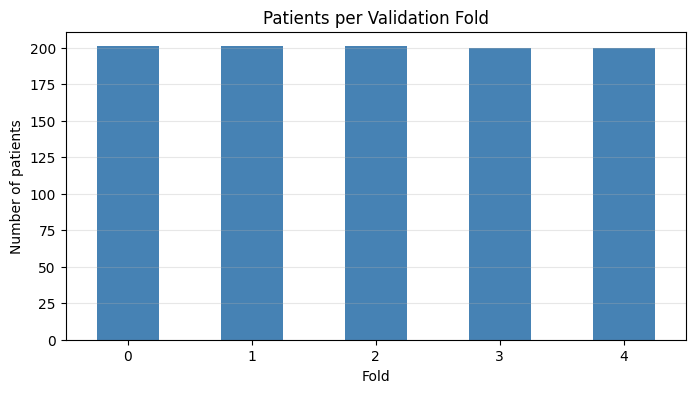

Fold 1: Train = 802, Validation = 201
Fold 2: Train = 802, Validation = 201
Fold 3: Train = 802, Validation = 201
Fold 4: Train = 803, Validation = 200
Fold 5: Train = 803, Validation = 200

All cross-validation integrity checks passed.


In [9]:
# ================================================================
# CELL 8 - CREATE 5-FOLD CROSS-VALIDATION SPLITS
# ================================================================

# Work only with the development set
cv_df = development_df.copy().reset_index(drop=True)

# Check cohort distribution
cohort_counts = cv_df["Cohort ID"].value_counts(dropna=False)

print("Patients per cohort:")
display(cohort_counts)

# Prepare stratification labels
stratification_labels = (
    cv_df["Cohort ID"]
    .fillna("Unknown")
    .astype(str)
)

# Check whether stratification is possible
if stratification_labels.value_counts().min() >= N_FOLDS:

    print("\nUsing StratifiedKFold by Cohort ID.")

    cv = StratifiedKFold(
        n_splits=N_FOLDS,
        shuffle=True,
        random_state=SEED
    )

    split_iterator = cv.split(
        cv_df,
        stratification_labels
    )

else:

    print(
        "\nWarning: At least one cohort has fewer than 5 patients."
    )
    print("Using standard KFold instead.")

    cv = KFold(
        n_splits=N_FOLDS,
        shuffle=True,
        random_state=SEED
    )

    split_iterator = cv.split(cv_df)

# Initialize fold column
cv_df["fold"] = -1

# Assign each patient to exactly one validation fold
for fold, (_, val_indices) in enumerate(split_iterator):

    cv_df.loc[val_indices, "fold"] = fold

# Verify assignments
assert (cv_df["fold"] >= 0).all()
assert cv_df["patient_folder"].is_unique

# Save fold assignments
FOLD_MANIFEST_PATH = OUTPUT_DIR / "5fold_manifest.csv"

cv_df.to_csv(
    FOLD_MANIFEST_PATH,
    index=False
)

print("\nCross-validation splits created.")
print("Saved to:", FOLD_MANIFEST_PATH)

print("\nPatients assigned to each fold:")
print(cv_df["fold"].value_counts().sort_index())

# ================================================================
# CELL 9 - VERIFY FOLD DISTRIBUTION
# ================================================================

print("Patients per fold:\n")

fold_counts = cv_df["fold"].value_counts().sort_index()

display(
    fold_counts.rename("Validation patients").to_frame()
)

print("\nCohort distribution per fold:\n")

cohort_fold_table = pd.crosstab(
    cv_df["fold"],
    cv_df["Cohort ID"]
)

display(cohort_fold_table)

# Plot fold distribution
plt.figure(figsize=(8, 4))

fold_counts.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Patients per Validation Fold")
plt.xlabel("Fold")
plt.ylabel("Number of patients")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

# ================================================================
# CELL 10 - VERIFY CROSS-VALIDATION INTEGRITY
# ================================================================

all_validation_ids = []

for fold in range(N_FOLDS):

    val_fold = cv_df[
        cv_df["fold"] == fold
    ]

    train_fold = cv_df[
        cv_df["fold"] != fold
    ]

    train_ids = set(
        train_fold["patient_folder"].astype(str)
    )

    val_ids = set(
        val_fold["patient_folder"].astype(str)
    )

    # Check no overlap
    assert train_ids.isdisjoint(val_ids), (
        f"Leakage detected in fold {fold + 1}"
    )

    all_validation_ids.extend(val_ids)

    print(
        f"Fold {fold + 1}: "
        f"Train = {len(train_ids)}, "
        f"Validation = {len(val_ids)}"
    )

# Every development patient must be validation exactly once
assert len(all_validation_ids) == len(set(all_validation_ids))
assert set(all_validation_ids) == set(
    cv_df["patient_folder"].astype(str)
)

# Test set must remain excluded
assert set(cv_df["patient_folder"].astype(str)).isdisjoint(
    set(test_df["patient_folder"].astype(str))
)

print("\nAll cross-validation integrity checks passed.")


In [11]:
# ================================================================
# CELL 11 - LABEL MAPPING AND PREPROCESSING CONFIGURATION
# ================================================================

# Original dataset labels -> consecutive training labels
LABEL_MAPPING = {
    0: 0,  # Background
    1: 1,  # Necrotic core
    2: 2,  # FLAIR signal hyperintensity
    4: 3   # Enhancing tumor
}

CLASS_NAMES = {
    0: "Background",
    1: "Necrotic core",
    2: "FLAIR signal hyperintensity",
    3: "Enhancing tumor"
}

# Normalization percentiles
LOWER_PERCENTILE = 0.5
UPPER_PERCENTILE = 99.5

# Patch sampling
SAMPLES_PER_PATIENT = 2
TUMOR_PATCH_PROBABILITY = 0.75

print("Label mapping:")
for original, training in LABEL_MAPPING.items():
    print(
        f"Original label {original} -> "
        f"Training label {training}: "
        f"{CLASS_NAMES[training]}"
    )

print("\nPatch size:", PATCH_SIZE)
print("Samples per patient:", SAMPLES_PER_PATIENT)

# ================================================================
# CELL 12 - MRI LOADING AND NORMALIZATION
# ================================================================

def normalize_mri(volume):
    """
    Percentile clipping followed by z-score normalization.
    Background voxels remain zero.
    """

    volume = np.asarray(
        volume,
        dtype=np.float32
    )

    nonzero_mask = volume != 0

    if not nonzero_mask.any():
        return np.zeros_like(volume, dtype=np.float32)

    values = volume[nonzero_mask]

    lower = np.percentile(
        values,
        LOWER_PERCENTILE
    )

    upper = np.percentile(
        values,
        UPPER_PERCENTILE
    )

    clipped = np.clip(
        volume,
        lower,
        upper
    )

    clipped_values = clipped[nonzero_mask]

    mean = clipped_values.mean()
    std = clipped_values.std()

    if std < 1e-8:
        normalized = np.zeros_like(volume, dtype=np.float32)
    else:
        normalized = (clipped - mean) / std

    normalized[~nonzero_mask] = 0

    return normalized.astype(np.float32)


def load_nifti_volume(path):
    """
    Load a NIfTI volume as a float32 NumPy array.
    """

    nii = nib.load(str(path))

    volume = nii.get_fdata(
        dtype=np.float32
    )

    return volume, nii


def load_patient_volumes(row):
    """
    Load and normalize the four MRI modalities.
    Load and remap the segmentation mask.
    """

    image_channels = []

    for modality in MODALITIES:

        path = row[f"{modality}_path"]

        volume, _ = load_nifti_volume(path)

        volume = normalize_mri(volume)

        image_channels.append(volume)

    # Shape: (4, X, Y, Z)
    image = np.stack(
        image_channels,
        axis=0
    )

    # Load segmentation mask
    mask, mask_nii = load_nifti_volume(
        row["MASK_path"]
    )

    # Verify spatial dimensions
    if image.shape[1:] != mask.shape:
        raise ValueError(
            f"Image/mask shape mismatch for "
            f"patient {row['patient_folder']}: "
            f"{image.shape[1:]} vs {mask.shape}"
        )

    # Verify original labels
    original_labels = set(
        np.unique(mask).astype(int)
    )

    unexpected_labels = (
        original_labels - set(LABEL_MAPPING.keys())
    )

    if unexpected_labels:
        raise ValueError(
            f"Unexpected labels for patient "
            f"{row['patient_folder']}: "
            f"{unexpected_labels}"
        )

    # Map original labels to consecutive classes
    mapped_mask = np.zeros(
        mask.shape,
        dtype=np.uint8
    )

    for original_label, training_label in LABEL_MAPPING.items():

        mapped_mask[
            mask == original_label
        ] = training_label

    return (
        image.astype(np.float32),
        mapped_mask,
        mask_nii
    )


print("MRI loading and normalization functions defined.")

Label mapping:
Original label 0 -> Training label 0: Background
Original label 1 -> Training label 1: Necrotic core
Original label 2 -> Training label 2: FLAIR signal hyperintensity
Original label 4 -> Training label 3: Enhancing tumor

Patch size: (64, 64, 64)
Samples per patient: 2
MRI loading and normalization functions defined.


In [12]:
# ================================================================
# CELL 13 - 3D PATCH EXTRACTION
# ================================================================

def extract_3d_patch(image, mask, patch_size, tumor_probability=0.75):
    """
    Extract a 3D patch from a multimodal MRI volume.

    image shape: (C, X, Y, Z)
    mask shape:  (X, Y, Z)
    """

    spatial_shape = mask.shape

    # Choose patch center
    tumor_coords = np.argwhere(mask > 0)

    use_tumor_center = (
        len(tumor_coords) > 0
        and random.random() < tumor_probability
    )

    if use_tumor_center:

        center = tumor_coords[
            random.randrange(len(tumor_coords))
        ]

    else:

        center = np.array([
            random.randrange(s)
            for s in spatial_shape
        ])

    # Pad volumes if smaller than requested patch
    pad_width = []

    for dim, patch_dim in zip(
        spatial_shape,
        patch_size
    ):

        total_pad = max(
            patch_dim - dim,
            0
        )

        before = total_pad // 2
        after = total_pad - before

        pad_width.append((before, after))

    image_pad = np.pad(
        image,
        [(0, 0)] + pad_width,
        mode="constant"
    )

    mask_pad = np.pad(
        mask,
        pad_width,
        mode="constant"
    )

    # Adjust center after padding
    center = center + np.array([
        p[0] for p in pad_width
    ])

    # Calculate patch boundaries
    starts = []

    for c, patch_dim, dim in zip(
        center,
        patch_size,
        mask_pad.shape
    ):

        start = int(c - patch_dim // 2)

        start = max(
            0,
            min(start, dim - patch_dim)
        )

        starts.append(start)

    slices = tuple(
        slice(start, start + patch_dim)
        for start, patch_dim in zip(
            starts,
            patch_size
        )
    )

    image_patch = image_pad[
        (slice(None),) + slices
    ]

    mask_patch = mask_pad[slices]

    return image_patch, mask_patch


print("3D patch extraction function defined.")

3D patch extraction function defined.


In [13]:
# ================================================================
# CELL 14 - DATA AUGMENTATION
# ================================================================

def augment_patch(image, mask):
    """
    Apply spatial and intensity augmentation.

    image: (C, X, Y, Z)
    mask:  (X, Y, Z)
    """

    # Random flips along spatial axes
    for axis in range(3):

        if random.random() < 0.5:

            image = np.flip(
                image,
                axis=axis + 1
            )

            mask = np.flip(
                mask,
                axis=axis
            )

    # Random 90-degree rotations in the first two axes
    k = random.randint(0, 3)

    image = np.rot90(
        image,
        k=k,
        axes=(1, 2)
    )

    mask = np.rot90(
        mask,
        k=k,
        axes=(0, 1)
    )

    # Per-modality intensity augmentation
    for channel in range(image.shape[0]):

        if random.random() < 0.5:

            scale = random.uniform(0.9, 1.1)
            shift = random.uniform(-0.1, 0.1)

            image[channel] = (
                image[channel] * scale + shift
            )

    # Ensure contiguous arrays (negative strides can break torch conversion)
    image = np.ascontiguousarray(
        image,
        dtype=np.float32
    )

    mask = np.ascontiguousarray(
        mask,
        dtype=np.int64
    )

    return image, mask


print("Data augmentation function defined.")

Data augmentation function defined.


In [15]:
# ================================================================
# CELL 15 - PYTORCH DATASET
# ================================================================

class Glioma3DDataset(Dataset):

    def __init__(
        self,
        dataframe,
        training=True,
        samples_per_patient=2
    ):

        self.df = dataframe.reset_index(drop=True)

        self.training = training

        self.samples_per_patient = (
            samples_per_patient if training else 1
        )

    def __len__(self):

        return (
            len(self.df) * self.samples_per_patient
        )

    def __getitem__(self, index):

        patient_index = (
            index // self.samples_per_patient
        )

        row = self.df.iloc[patient_index]

        # Load full MRI and mask
        image, mask, _ = load_patient_volumes(row)

        if self.training:

            image, mask = extract_3d_patch(
                image,
                mask,
                PATCH_SIZE,
                tumor_probability=TUMOR_PATCH_PROBABILITY
            )

            image, mask = augment_patch(
                image,
                mask
            )

        else:

            image = np.ascontiguousarray(
                image,
                dtype=np.float32
            )

            mask = np.ascontiguousarray(
                mask,
                dtype=np.int64
            )

        return {
            "image": torch.from_numpy(image),
            "mask": torch.from_numpy(mask),
            "patient_id": str(row["patient_folder"])
        }


print("Glioma3DDataset class defined.")

Glioma3DDataset class defined.


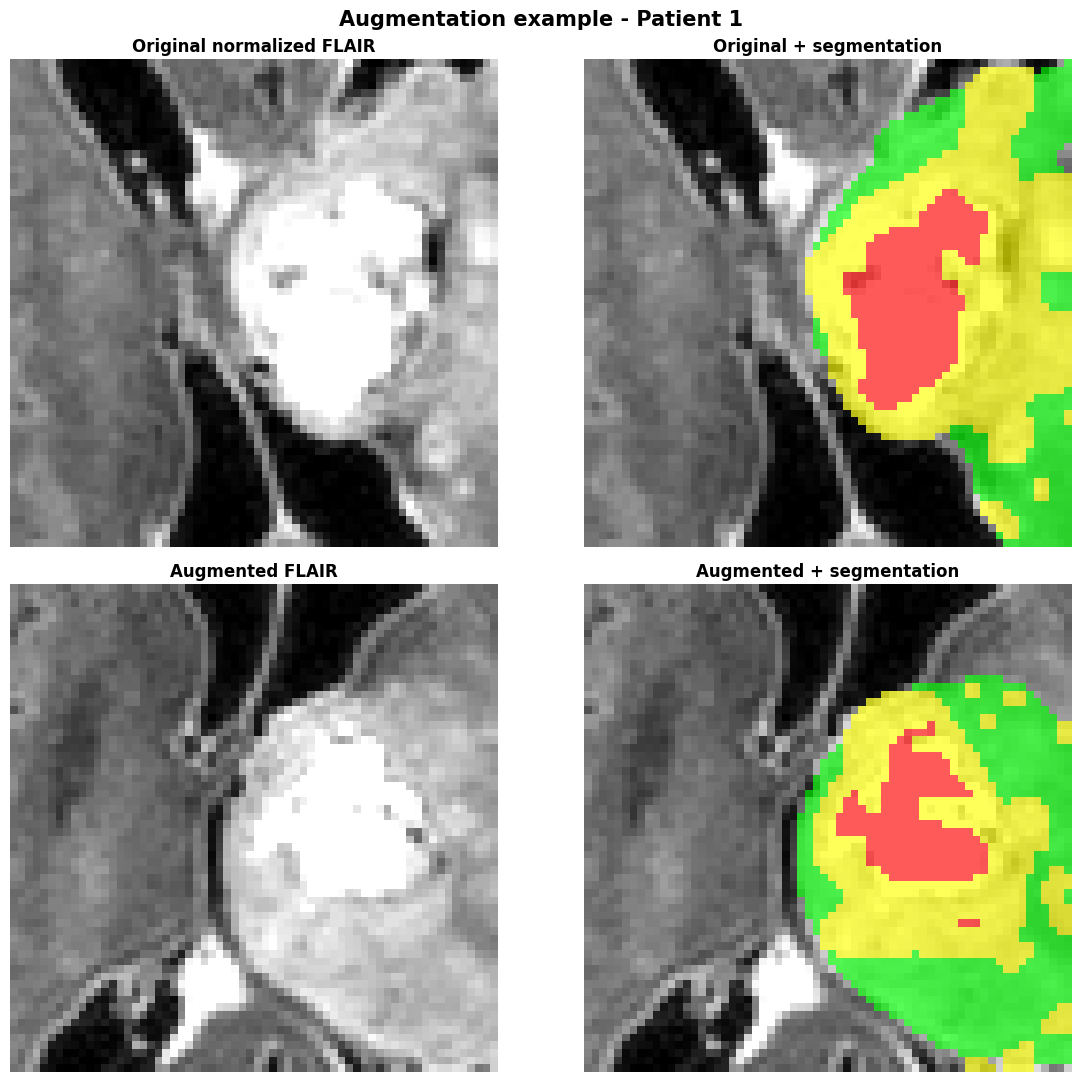

Patient: 1
Displayed axial slice: 34

Original mask labels: [0 1 2 3]
Augmented mask labels: [0 1 2 3]


In [19]:
# ================================================================
# CELL 17 - VISUALIZE PREPROCESSING AND AUGMENTATION
# ================================================================

def visualize_augmentation(
    dataframe,
    patient_index=0,
    slice_index=None
):
    """
    Visualize the effect of preprocessing and augmentation.

    Shows:
        1. Original normalized FLAIR
        2. Original segmentation
        3. Augmented FLAIR
        4. Augmented segmentation
    """

    row = dataframe.iloc[patient_index]

    # ------------------------------------------------------------
    # Load full patient volume
    # ------------------------------------------------------------

    image, mask, _ = load_patient_volumes(row)

    # ------------------------------------------------------------
    # Extract one patch
    # ------------------------------------------------------------

    original_image, original_mask = extract_3d_patch(
        image,
        mask,
        PATCH_SIZE,
        tumor_probability=1.0
    )

    # Make a copy before augmentation
    augmented_image = original_image.copy()
    augmented_mask = original_mask.copy()

    # ------------------------------------------------------------
    # Apply augmentation
    # ------------------------------------------------------------

    augmented_image, augmented_mask = augment_patch(
        augmented_image,
        augmented_mask
    )

    # ------------------------------------------------------------
    # Select slice
    # ------------------------------------------------------------

    if slice_index is None:

        # Prefer a slice containing tumor
        tumor_slices = np.where(
            original_mask.sum(axis=(0, 1)) > 0
        )[0]

        if len(tumor_slices) > 0:
            slice_index = int(
                tumor_slices[len(tumor_slices) // 2]
            )
        else:
            slice_index = PATCH_SIZE[2] // 2

    # ------------------------------------------------------------
    # Extract FLAIR slices
    # ------------------------------------------------------------

    original_flair = np.rot90(
        original_image[0, :, :, slice_index]
    )

    original_seg = np.rot90(
        original_mask[:, :, slice_index]
    )

    augmented_flair = np.rot90(
        augmented_image[0, :, :, slice_index]
    )

    augmented_seg = np.rot90(
        augmented_mask[:, :, slice_index]
    )

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(12, 11)
    )

    # ------------------------------------------------------------
    # Fixed segmentation colormap
    # ------------------------------------------------------------

    seg_cmap = ListedColormap([
        (0, 0, 0, 0),       # background
        (1, 0, 0, 0.65),    # necrotic
        (0, 1, 0, 0.65),    # FLAIR hyperintensity
        (1, 1, 0, 0.65)     # enhancing
    ])

    # ------------------------------------------------------------
    # Original FLAIR
    # ------------------------------------------------------------

    axes[0, 0].imshow(
        original_flair,
        cmap="gray"
    )

    axes[0, 0].set_title(
        "Original normalized FLAIR",
        fontsize=12,
        fontweight="bold"
    )

    axes[0, 0].axis("off")

    # ------------------------------------------------------------
    # Original segmentation
    # ------------------------------------------------------------

    axes[0, 1].imshow(
        original_flair,
        cmap="gray"
    )

    axes[0, 1].imshow(
        original_seg,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )

    axes[0, 1].set_title(
        "Original + segmentation",
        fontsize=12,
        fontweight="bold"
    )

    axes[0, 1].axis("off")

    # ------------------------------------------------------------
    # Augmented FLAIR
    # ------------------------------------------------------------

    axes[1, 0].imshow(
        augmented_flair,
        cmap="gray"
    )

    axes[1, 0].set_title(
        "Augmented FLAIR",
        fontsize=12,
        fontweight="bold"
    )

    axes[1, 0].axis("off")

    # ------------------------------------------------------------
    # Augmented segmentation
    # ------------------------------------------------------------

    axes[1, 1].imshow(
        augmented_flair,
        cmap="gray"
    )

    axes[1, 1].imshow(
        augmented_seg,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )

    axes[1, 1].set_title(
        "Augmented + segmentation",
        fontsize=12,
        fontweight="bold"
    )

    axes[1, 1].axis("off")

    # ------------------------------------------------------------
    # Figure title
    # ------------------------------------------------------------

    plt.suptitle(
        f"Augmentation example - Patient {row['patient_folder']}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.show()

    # ------------------------------------------------------------
    # Print information
    # ------------------------------------------------------------

    print(f"Patient: {row['patient_folder']}")
    print(f"Displayed axial slice: {slice_index}")

    print("\nOriginal mask labels:",
          np.unique(original_mask))

    print("Augmented mask labels:",
          np.unique(augmented_mask))


# ---------------------------------------------------------------
# Run visualization
# ---------------------------------------------------------------

visualize_augmentation(
    development_df,
    patient_index=0
)

In [27]:
# ================================================================
# CELL 19 - 3D U-NET ARCHITECTURE
# ================================================================

class DoubleConv3D(nn.Module):
    """
    Two consecutive 3D convolutional blocks:
    Conv3D -> InstanceNorm3D -> ReLU
    Conv3D -> InstanceNorm3D -> ReLU
    """
    
    def __init__(self, in_channels, out_channels):
        super().__init__()
        
        self.block = nn.Sequential(
            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.InstanceNorm3d(out_channels),
            nn.ReLU(inplace=True),
            
            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.InstanceNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )
    
    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    """
    Standard 3D U-Net for multimodal MRI segmentation.

    Input:
        B x 4 x 64 x 64 x 64

    Output:
        B x 4 x 64 x 64 x 64

    The decoder automatically matches the spatial dimensions
    of the skip connections before concatenation. This prevents
    shape mismatch errors caused by odd spatial dimensions
    after repeated downsampling.
    """

    def __init__(
        self,
        in_channels=4,
        out_channels=4,
        base_channels=8
    ):
        super().__init__()

        c1 = base_channels
        c2 = base_channels * 2
        c3 = base_channels * 4
        c4 = base_channels * 8

        # --------------------------------------------------------
        # Encoder
        # --------------------------------------------------------
        self.enc1 = DoubleConv3D(in_channels, c1)
        self.pool1 = nn.MaxPool3d(
            kernel_size=2,
            stride=2
        )

        self.enc2 = DoubleConv3D(c1, c2)
        self.pool2 = nn.MaxPool3d(
            kernel_size=2,
            stride=2
        )

        self.enc3 = DoubleConv3D(c2, c3)
        self.pool3 = nn.MaxPool3d(
            kernel_size=2,
            stride=2
        )

        self.enc4 = DoubleConv3D(c3, c4)
        self.pool4 = nn.MaxPool3d(
            kernel_size=2,
            stride=2
        )

        # --------------------------------------------------------
        # Bottleneck
        # --------------------------------------------------------
        self.bottleneck = DoubleConv3D(
            c4,
            c4 * 2
        )

        # --------------------------------------------------------
        # Decoder
        # --------------------------------------------------------
        self.up4 = nn.ConvTranspose3d(
            c4 * 2,
            c4,
            kernel_size=2,
            stride=2
        )
        self.dec4 = DoubleConv3D(
            c4 * 2,
            c4
        )

        self.up3 = nn.ConvTranspose3d(
            c4,
            c3,
            kernel_size=2,
            stride=2
        )
        self.dec3 = DoubleConv3D(
            c3 * 2,
            c3
        )

        self.up2 = nn.ConvTranspose3d(
            c3,
            c2,
            kernel_size=2,
            stride=2
        )
        self.dec2 = DoubleConv3D(
            c2 * 2,
            c2
        )

        self.up1 = nn.ConvTranspose3d(
            c2,
            c1,
            kernel_size=2,
            stride=2
        )
        self.dec1 = DoubleConv3D(
            c1 * 2,
            c1
        )

        # --------------------------------------------------------
        # Final segmentation layer
        # --------------------------------------------------------
        self.final_conv = nn.Conv3d(
            c1,
            out_channels,
            kernel_size=1
        )

    @staticmethod
    def match_spatial_size(x, reference):
        """
        Match the spatial dimensions of x to reference.

        This is used before skip connections to avoid errors
        such as:
            Expected size 18 but got size 19

        If dimensions differ by one or more voxels, trilinear
        interpolation adjusts x to exactly match reference.
        """

        if x.shape[2:] != reference.shape[2:]:
            x = F.interpolate(
                x,
                size=reference.shape[2:],
                mode="trilinear",
                align_corners=False
            )

        return x

    def forward(self, x):

        # --------------------------------------------------------
        # Encoder
        # --------------------------------------------------------
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool1(e1)
        )

        e3 = self.enc3(
            self.pool2(e2)
        )

        e4 = self.enc4(
            self.pool3(e3)
        )

        # --------------------------------------------------------
        # Bottleneck
        # --------------------------------------------------------
        b = self.bottleneck(
            self.pool4(e4)
        )

        # --------------------------------------------------------
        # Decoder + skip connections
        # --------------------------------------------------------

        # Decoder level 4
        d4 = self.up4(b)
        d4 = self.match_spatial_size(d4, e4)
        d4 = torch.cat(
            [d4, e4],
            dim=1
        )
        d4 = self.dec4(d4)

        # Decoder level 3
        d3 = self.up3(d4)
        d3 = self.match_spatial_size(d3, e3)
        d3 = torch.cat(
            [d3, e3],
            dim=1
        )
        d3 = self.dec3(d3)

        # Decoder level 2
        d2 = self.up2(d3)
        d2 = self.match_spatial_size(d2, e2)
        d2 = torch.cat(
            [d2, e2],
            dim=1
        )
        d2 = self.dec2(d2)

        # Decoder level 1
        d1 = self.up1(d2)
        d1 = self.match_spatial_size(d1, e1)
        d1 = torch.cat(
            [d1, e1],
            dim=1
        )
        d1 = self.dec1(d1)

        # --------------------------------------------------------
        # Final output
        # --------------------------------------------------------
        return self.final_conv(d1)


print("3D U-Net class defined successfully.")

# ================================================================
# CELL 20 - MODEL INITIALIZATION AND SHAPE TEST
# ================================================================

model = UNet3D(
    in_channels=NUM_INPUT_CHANNELS,
    out_channels=NUM_CLASSES,
    base_channels=BASE_CHANNELS
)

# Use DataParallel when multiple GPUs are available
if torch.cuda.is_available() and torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

model = model.to(DEVICE)

print(model)

# ---------------------------------------------------------------
# Parameter count
# ---------------------------------------------------------------
num_parameters = sum(
    p.numel() for p in model.parameters()
)

num_trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{num_parameters:,}")
print("Trainable parameters:", f"{num_trainable_parameters:,}")

# ---------------------------------------------------------------
# Forward-pass smoke test
# ---------------------------------------------------------------
with torch.no_grad():
    dummy_input = torch.randn(
        1,
        NUM_INPUT_CHANNELS,
        *PATCH_SIZE,
        device=DEVICE
    )

    dummy_output = model(dummy_input)

print("\nInput shape :", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))

assert dummy_output.shape == (
    1,
    NUM_CLASSES,
    *PATCH_SIZE
)

assert torch.isfinite(dummy_output).all()

print("\n3D U-Net forward pass: OK")

3D U-Net class defined successfully.
UNet3D(
  (enc1): DoubleConv3D(
    (block): Sequential(
      (0): Conv3d(4, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (1): InstanceNorm3d(8, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
      (2): ReLU(inplace=True)
      (3): Conv3d(8, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (4): InstanceNorm3d(8, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
      (5): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): DoubleConv3D(
    (block): Sequential(
      (0): Conv3d(8, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
      (1): InstanceNorm3d(16, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
      (2): ReLU(inplace=True)
      (3): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False

In [28]:
# ================================================================
# CELL 21 - LOSS FUNCTIONS
# ================================================================

class SoftDiceLoss(nn.Module):
    """
    Multi-class soft Dice loss.
    
    Background class (0) is excluded from the Dice calculation.
    """

    def __init__(self, smooth=1e-5):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        """
        logits:
            [B, C, D, H, W]

        targets:
            [B, D, H, W]
        """

        num_classes = logits.shape[1]

        # Convert logits to probabilities
        probs = torch.softmax(logits, dim=1)

        # One-hot encode target
        targets_one_hot = F.one_hot(
            targets.long(),
            num_classes=num_classes
        )

        # [B, D, H, W, C] -> [B, C, D, H, W]
        targets_one_hot = targets_one_hot.permute(
            0, 4, 1, 2, 3
        ).float()

        # Exclude background
        probs = probs[:, 1:]
        targets_one_hot = targets_one_hot[:, 1:]

        # Flatten spatial dimensions
        probs = probs.reshape(
            probs.shape[0],
            probs.shape[1],
            -1
        )

        targets_one_hot = targets_one_hot.reshape(
            targets_one_hot.shape[0],
            targets_one_hot.shape[1],
            -1
        )

        # Dice per class and patient
        intersection = (
            probs * targets_one_hot
        ).sum(dim=2)

        denominator = (
            probs.sum(dim=2)
            + targets_one_hot.sum(dim=2)
        )

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            denominator + self.smooth
        )

        # Mean across foreground classes and batch
        dice_loss = 1.0 - dice.mean()

        return dice_loss


class CombinedLoss(nn.Module):
    """
    Combined segmentation loss:

        0.5 * Cross Entropy
        +
        0.5 * Soft Dice
    """

    def __init__(
        self,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

        self.ce = nn.CrossEntropyLoss()
        self.dice = SoftDiceLoss()

    def forward(self, logits, targets):

        ce_loss = self.ce(logits, targets)
        dice_loss = self.dice(logits, targets)

        total_loss = (
            self.ce_weight * ce_loss
            +
            self.dice_weight * dice_loss
        )

        return total_loss, ce_loss, dice_loss


criterion = CombinedLoss(
    ce_weight=0.5,
    dice_weight=0.5
)

print("Loss functions defined successfully.")

# ================================================================
# CELL 23 - DICE AND IoU METRICS
# ================================================================

def dice_score_per_class(
    prediction,
    target,
    num_classes=NUM_CLASSES,
    include_background=False
):
    """
    Computes Dice score for each class.

    prediction:
        [B, D, H, W]

    target:
        [B, D, H, W]
    """

    scores = []

    start_class = 0 if include_background else 1

    for class_id in range(start_class, num_classes):

        pred_class = (prediction == class_id)
        target_class = (target == class_id)

        intersection = (
            pred_class & target_class
        ).sum().float()

        pred_volume = pred_class.sum().float()
        target_volume = target_class.sum().float()

        denominator = pred_volume + target_volume

        if denominator == 0:
            # Both prediction and target are empty
            dice = torch.tensor(
                1.0,
                device=prediction.device
            )
        else:
            dice = (
                2.0 * intersection
                / denominator
            )

        scores.append(dice.item())

    return scores


def iou_score_per_class(
    prediction,
    target,
    num_classes=NUM_CLASSES,
    include_background=False
):
    """
    Computes IoU score for each class.
    """

    scores = []

    start_class = 0 if include_background else 1

    for class_id in range(start_class, num_classes):

        pred_class = (prediction == class_id)
        target_class = (target == class_id)

        intersection = (
            pred_class & target_class
        ).sum().float()

        union = (
            pred_class | target_class
        ).sum().float()

        if union == 0:
            iou = torch.tensor(
                1.0,
                device=prediction.device
            )
        else:
            iou = intersection / union

        scores.append(iou.item())

    return scores


print("Dice and IoU metric functions defined successfully.")

Loss functions defined successfully.
Dice and IoU metric functions defined successfully.


In [29]:
# ================================================================
# CELL 25 - TRAINING UTILITIES
# ================================================================

import time
from tqdm.auto import tqdm


def get_model_state_dict(model):
    """
    Returns the state_dict independently of whether
    the model is wrapped in DataParallel.
    """
    if isinstance(model, nn.DataParallel):
        return model.module.state_dict()
    return model.state_dict()


def create_model():
    """
    Creates a fresh 3D U-Net for each fold.
    """

    model = UNet3D(
        in_channels=NUM_INPUT_CHANNELS,
        out_channels=NUM_CLASSES,
        base_channels=BASE_CHANNELS
    )

    if torch.cuda.is_available() and torch.cuda.device_count() > 1:
        model = nn.DataParallel(model)

    model = model.to(DEVICE)

    return model


def create_optimizer(model):
    """
    AdamW optimizer.
    """

    return torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )


def compute_batch_metrics(logits, targets):
    """
    Computes mean Dice and IoU across the foreground classes
    for a batch.
    """

    predictions = torch.argmax(logits, dim=1)

    dice_values = dice_score_per_class(
        predictions,
        targets,
        num_classes=NUM_CLASSES,
        include_background=False
    )

    iou_values = iou_score_per_class(
        predictions,
        targets,
        num_classes=NUM_CLASSES,
        include_background=False
    )

    return (
        float(np.mean(dice_values)),
        float(np.mean(iou_values))
    )


print("Training utilities defined successfully.")

# ================================================================
# CELL 26 - TRAIN ONE EPOCH
# ================================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler
):
    model.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice_loss = 0.0

    running_dice = 0.0
    running_iou = 0.0

    num_batches = 0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for batch in progress_bar:

        images = batch["image"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # --------------------------------------------------------
        # Mixed precision forward pass
        # --------------------------------------------------------
        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):

            logits = model(images)

            total_loss, ce_loss, dice_loss = criterion(
                logits,
                masks
            )

        # --------------------------------------------------------
        # Backpropagation
        # --------------------------------------------------------
        scaler.scale(total_loss).backward()

        scaler.step(optimizer)
        scaler.update()

        # --------------------------------------------------------
        # Metrics
        # --------------------------------------------------------
        batch_dice, batch_iou = compute_batch_metrics(
            logits.detach(),
            masks
        )

        running_loss += total_loss.item()
        running_ce += ce_loss.item()
        running_dice_loss += dice_loss.item()

        running_dice += batch_dice
        running_iou += batch_iou

        num_batches += 1

        progress_bar.set_postfix(
            loss=f"{total_loss.item():.4f}",
            dice=f"{batch_dice:.4f}"
        )

    return {
        "loss": running_loss / num_batches,
        "ce_loss": running_ce / num_batches,
        "dice_loss": running_dice_loss / num_batches,
        "dice": running_dice / num_batches,
        "iou": running_iou / num_batches
    }

# ================================================================
# CELL 27 - VALIDATION
# ================================================================

def validate_one_epoch(
    model,
    loader,
    criterion
):
    model.eval()

    running_loss = 0.0
    running_ce = 0.0
    running_dice_loss = 0.0

    running_dice = 0.0
    running_iou = 0.0

    num_batches = 0

    with torch.no_grad():

        progress_bar = tqdm(
            loader,
            desc="Validation",
            leave=False
        )

        for batch in progress_bar:

            images = batch["image"].to(
                DEVICE,
                non_blocking=True
            )

            masks = batch["mask"].to(
                DEVICE,
                non_blocking=True
            )

            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):

                logits = model(images)

                total_loss, ce_loss, dice_loss = criterion(
                    logits,
                    masks
                )

            batch_dice, batch_iou = compute_batch_metrics(
                logits,
                masks
            )

            running_loss += total_loss.item()
            running_ce += ce_loss.item()
            running_dice_loss += dice_loss.item()

            running_dice += batch_dice
            running_iou += batch_iou

            num_batches += 1

            progress_bar.set_postfix(
                loss=f"{total_loss.item():.4f}",
                dice=f"{batch_dice:.4f}"
            )

    return {
        "loss": running_loss / num_batches,
        "ce_loss": running_ce / num_batches,
        "dice_loss": running_dice_loss / num_batches,
        "dice": running_dice / num_batches,
        "iou": running_iou / num_batches
    }



Training utilities defined successfully.


In [ ]:
# ================================================================
# CELL 28 - 5-FOLD CROSS-VALIDATION TRAINING
# ================================================================

# ---------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------
set_seed(SEED)

# ---------------------------------------------------------------
# DataLoader settings
# ---------------------------------------------------------------
loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
}

# Persistent workers only if workers > 0
if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True


# ---------------------------------------------------------------
# Storage for all fold results
# ---------------------------------------------------------------
all_fold_results = []
all_fold_histories = []


# ===============================================================
# LOOP OVER THE 5 FOLDS
# ===============================================================

for fold in range(N_FOLDS):

    print("\n")
    print("=" * 70)
    print(f"STARTING FOLD {fold}")
    print("=" * 70)

    # -----------------------------------------------------------
    # Split patients
    # -----------------------------------------------------------
    train_fold_df = cv_df[
        cv_df["fold"] != fold
    ].copy().reset_index(drop=True)

    val_fold_df = cv_df[
        cv_df["fold"] == fold
    ].copy().reset_index(drop=True)

    print(f"Training patients   : {len(train_fold_df)}")
    print(f"Validation patients : {len(val_fold_df)}")

    # -----------------------------------------------------------
    # Dataset
    # -----------------------------------------------------------
    train_dataset = Glioma3DDataset(
        train_fold_df,
        training=True
    )

    val_dataset = Glioma3DDataset(
        val_fold_df,
        training=False
    )

    # -----------------------------------------------------------
    # DataLoaders
    # -----------------------------------------------------------
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=True
)

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
)

    print(f"Training patches per epoch   : {len(train_dataset)}")
    print(f"Validation samples per epoch : {len(val_dataset)}")

    # -----------------------------------------------------------
    # Fresh model
    # -----------------------------------------------------------
    model = create_model()

    # -----------------------------------------------------------
    # Optimizer
    # -----------------------------------------------------------
    optimizer = create_optimizer(model)

    # -----------------------------------------------------------
    # Loss
    # -----------------------------------------------------------
    criterion = CombinedLoss(
        ce_weight=0.5,
        dice_weight=0.5
    )

    # -----------------------------------------------------------
    # Mixed precision scaler
    # -----------------------------------------------------------
    scaler = torch.cuda.amp.GradScaler(
        enabled=torch.cuda.is_available()
    )

    # -----------------------------------------------------------
    # History
    # -----------------------------------------------------------
    history = []

    best_val_loss = float("inf")
    best_val_dice = -float("inf")

    epochs_without_improvement = 0
    best_epoch = 0

    fold_start_time = time.time()

    # ===========================================================
    # EPOCH LOOP
    # ===========================================================

    for epoch in range(1, MAX_EPOCHS + 1):

        epoch_start_time = time.time()

        print("\n")
        print("-" * 70)
        print(
            f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS}"
        )
        print("-" * 70)

        # -------------------------------------------------------
        # Training
        # -------------------------------------------------------
        train_metrics = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            scaler
        )

        # -------------------------------------------------------
        # Validation
        # -------------------------------------------------------
        val_metrics = validate_one_epoch(
            model,
            val_loader,
            criterion
        )

        epoch_time = time.time() - epoch_start_time

        # -------------------------------------------------------
        # Store metrics
        # -------------------------------------------------------
        epoch_result = {
            "fold": fold,
            "epoch": epoch,

            "train_loss": train_metrics["loss"],
            "train_ce_loss": train_metrics["ce_loss"],
            "train_dice_loss": train_metrics["dice_loss"],
            "train_dice": train_metrics["dice"],
            "train_iou": train_metrics["iou"],

            "val_loss": val_metrics["loss"],
            "val_ce_loss": val_metrics["ce_loss"],
            "val_dice_loss": val_metrics["dice_loss"],
            "val_dice": val_metrics["dice"],
            "val_iou": val_metrics["iou"],

            "epoch_time_seconds": epoch_time
        }

        history.append(epoch_result)

        # -------------------------------------------------------
        # Print epoch summary
        # -------------------------------------------------------
        print(
            f"\nTrain loss: {train_metrics['loss']:.4f}"
            f" | Train Dice: {train_metrics['dice']:.4f}"
            f" | Train IoU: {train_metrics['iou']:.4f}"
        )

        print(
            f"Val loss:   {val_metrics['loss']:.4f}"
            f" | Val Dice:   {val_metrics['dice']:.4f}"
            f" | Val IoU:    {val_metrics['iou']:.4f}"
        )

        print(
            f"Epoch time: {epoch_time / 60:.2f} min"
        )

        # -------------------------------------------------------
        # Save best checkpoint
        #
        # Primary criterion:
        # validation loss
        # -------------------------------------------------------
        if val_metrics["loss"] < best_val_loss:

            best_val_loss = val_metrics["loss"]
            best_val_dice = val_metrics["dice"]
            best_epoch = epoch

            epochs_without_improvement = 0

            checkpoint = {
                "fold": fold,
                "epoch": epoch,

                "model_state_dict":
                    get_model_state_dict(model),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_val_loss":
                    best_val_loss,

                "best_val_dice":
                    best_val_dice,

                "config": {
                    "patch_size": PATCH_SIZE,
                    "batch_size": BATCH_SIZE,
                    "base_channels": BASE_CHANNELS,
                    "learning_rate": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY,
                    "num_classes": NUM_CLASSES,
                    "num_input_channels": NUM_INPUT_CHANNELS
                }
            }

            checkpoint_path = (
                CHECKPOINT_DIR /
                f"unet3d_fold{fold}_best.pth"
            )

            torch.save(
                checkpoint,
                checkpoint_path
            )

            print(
                f"✓ Best checkpoint saved: "
                f"{checkpoint_path.name}"
            )

        else:

            epochs_without_improvement += 1

            print(
                f"No improvement for "
                f"{epochs_without_improvement} epoch(s)."
            )

        # -------------------------------------------------------
        # Early stopping
        # -------------------------------------------------------
        if epochs_without_improvement >= PATIENCE:

            print(
                f"\nEarly stopping triggered "
                f"after {PATIENCE} epochs without improvement."
            )

            break

    # ===========================================================
    # END OF FOLD
    # ===========================================================

    fold_time = time.time() - fold_start_time

    history_df = pd.DataFrame(history)

    history_path = (
        RESULTS_DIR /
        f"fold_{fold}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    # Best epoch
    best_row = history_df.loc[
        history_df["val_loss"].idxmin()
    ]

    fold_result = {
        "fold": fold,
        "best_epoch": int(best_row["epoch"]),
        "best_val_loss": float(best_row["val_loss"]),
        "best_val_dice": float(best_row["val_dice"]),
        "best_val_iou": float(best_row["val_iou"]),
        "training_time_minutes": fold_time / 60.0
    }

    all_fold_results.append(fold_result)
    all_fold_histories.append(history_df)

    print("\n")
    print("=" * 70)
    print(f"FOLD {fold} COMPLETED")
    print("=" * 70)

    print(
        f"Best epoch : {fold_result['best_epoch']}"
    )

    print(
        f"Best val loss : "
        f"{fold_result['best_val_loss']:.4f}"
    )

    print(
        f"Best val Dice : "
        f"{fold_result['best_val_dice']:.4f}"
    )

    print(
        f"Best val IoU : "
        f"{fold_result['best_val_iou']:.4f}"
    )

    print(
        f"Training time : "
        f"{fold_result['training_time_minutes']:.2f} min"
    )

    # -----------------------------------------------------------
    # Free memory before next fold
    # -----------------------------------------------------------
    del model
    del optimizer
    del train_dataset
    del val_dataset
    del train_loader
    del val_loader
    del scaler

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ===============================================================
# SAVE FINAL CV RESULTS
# ===============================================================

fold_results_df = pd.DataFrame(
    all_fold_results
)

fold_results_path = (
    RESULTS_DIR /
    "5fold_summary.csv"
)

fold_results_df.to_csv(
    fold_results_path,
    index=False
)

print("\n")
print("=" * 70)
print("5-FOLD CROSS-VALIDATION COMPLETED")
print("=" * 70)

display(fold_results_df)

print("\nMean validation Dice:",
      fold_results_df["best_val_dice"].mean())

print("Std validation Dice:",
      fold_results_df["best_val_dice"].std())

print("\nMean validation IoU:",
      fold_results_df["best_val_iou"].mean())

print("Std validation IoU:",
      fold_results_df["best_val_iou"].std())

print("\nResults saved to:")
print(fold_results_path)



STARTING FOLD 0
Training patients   : 802
Validation patients : 201
Training patches per epoch   : 1604
Validation samples per epoch : 201


----------------------------------------------------------------------
Fold 0 | Epoch 1/50
----------------------------------------------------------------------


Training:   0%|          | 0/802 [00:00<?, ?it/s]

In [ ]:
# ================================================================
# CELL 29 - TRAINING / VALIDATION CURVES
# ================================================================

fig, axes = plt.subplots(
    3,
    2,
    figsize=(16, 15)
)

for fold in range(N_FOLDS):

    history_path = (
        RESULTS_DIR /
        f"fold_{fold}_history.csv"
    )

    history = pd.read_csv(history_path)

    # ------------------------------------------------------------
    # Loss
    # ------------------------------------------------------------
    axes[0, 0].plot(
        history["epoch"],
        history["train_loss"],
        label=f"Fold {fold}",
        linewidth=2
    )

    axes[0, 1].plot(
        history["epoch"],
        history["val_loss"],
        label=f"Fold {fold}",
        linewidth=2
    )

    # ------------------------------------------------------------
    # Dice
    # ------------------------------------------------------------
    axes[1, 0].plot(
        history["epoch"],
        history["train_dice"],
        label=f"Fold {fold}",
        linewidth=2
    )

    axes[1, 1].plot(
        history["epoch"],
        history["val_dice"],
        label=f"Fold {fold}",
        linewidth=2
    )

    # ------------------------------------------------------------
    # IoU
    # ------------------------------------------------------------
    axes[2, 0].plot(
        history["epoch"],
        history["train_iou"],
        label=f"Fold {fold}",
        linewidth=2
    )

    axes[2, 1].plot(
        history["epoch"],
        history["val_iou"],
        label=f"Fold {fold}",
        linewidth=2
    )


# ================================================================
# Formatting
# ================================================================

axes[0, 0].set_title(
    "Training Loss",
    fontsize=14,
    fontweight="bold"
)

axes[0, 1].set_title(
    "Validation Loss",
    fontsize=14,
    fontweight="bold"
)

axes[1, 0].set_title(
    "Training Dice",
    fontsize=14,
    fontweight="bold"
)

axes[1, 1].set_title(
    "Validation Dice",
    fontsize=14,
    fontweight="bold"
)

axes[2, 0].set_title(
    "Training IoU",
    fontsize=14,
    fontweight="bold"
)

axes[2, 1].set_title(
    "Validation IoU",
    fontsize=14,
    fontweight="bold"
)


for ax in axes.flat:

    ax.set_xlabel("Epoch")
    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend(
        fontsize=9
    )

axes[0, 0].set_ylabel("Loss")
axes[0, 1].set_ylabel("Loss")

axes[1, 0].set_ylabel("Dice")
axes[1, 1].set_ylabel("Dice")

axes[2, 0].set_ylabel("IoU")
axes[2, 1].set_ylabel("IoU")

plt.suptitle(
    "3D U-Net 5-Fold Cross-Validation Training Curves",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

curve_path = (
    RESULTS_DIR /
    "5fold_training_curves.png"
)

plt.savefig(
    curve_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Training curves saved to: {curve_path}")

In [ ]:
# ================================================================
# CELL 30 - LOSS CURVES FOR ALL FOLDS
# ================================================================

plt.figure(figsize=(12, 7))

for fold in range(N_FOLDS):

    history_path = (
        RESULTS_DIR /
        f"fold_{fold}_history.csv"
    )

    history = pd.read_csv(history_path)

    plt.plot(
        history["epoch"],
        history["train_loss"],
        linestyle="-",
        linewidth=1.8,
        alpha=0.8,
        label=f"Fold {fold} - Train"
    )

    plt.plot(
        history["epoch"],
        history["val_loss"],
        linestyle="--",
        linewidth=1.8,
        alpha=0.8,
        label=f"Fold {fold} - Validation"
    )

plt.xlabel(
    "Epoch",
    fontsize=12
)

plt.ylabel(
    "Combined Loss",
    fontsize=12
)

plt.title(
    "3D U-Net Training and Validation Loss",
    fontsize=15,
    fontweight="bold"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

loss_curve_path = (
    RESULTS_DIR /
    "5fold_loss_curves.png"
)

plt.savefig(
    loss_curve_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Loss curves saved to: {loss_curve_path}")

In [ ]:
# ================================================================
# CELL 32 - LOAD BEST CHECKPOINT AND VISUALIZE
# ================================================================

FOLD_TO_VISUALIZE = 0

checkpoint_path = (
    CHECKPOINT_DIR /
    f"unet3d_fold{FOLD_TO_VISUALIZE}_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

visualization_model = create_model()

visualization_model.load_state_dict(
    checkpoint["model_state_dict"]
)

visualization_model.eval()

fold_val_df = cv_df[
    cv_df["fold"] == FOLD_TO_VISUALIZE
].copy().reset_index(drop=True)

print(
    f"Loaded checkpoint from fold "
    f"{FOLD_TO_VISUALIZE}"
)

print(
    f"Validation patients available: "
    f"{len(fold_val_df)}"
)

visualize_prediction(
    visualization_model,
    fold_val_df,
    patient_index=0
)

# ================================================================
# CELL 33 - VISUALIZE MULTIPLE VALIDATION PREDICTIONS
# ================================================================

FOLD_TO_VISUALIZE = 0
N_PATIENTS_TO_SHOW = 4

fold_val_df = cv_df[
    cv_df["fold"] == FOLD_TO_VISUALIZE
].copy().reset_index(drop=True)

checkpoint_path = (
    CHECKPOINT_DIR /
    f"unet3d_fold{FOLD_TO_VISUALIZE}_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

visualization_model = create_model()

visualization_model.load_state_dict(
    checkpoint["model_state_dict"]
)

visualization_model.eval()

for patient_index in range(
    min(N_PATIENTS_TO_SHOW, len(fold_val_df))
):

    print("\n" + "=" * 60)

    visualize_prediction(
        visualization_model,
        fold_val_df,
        patient_index=patient_index
    )